In [1]:
import urllib.request

# Enlace directo al tile/cuadrícula que cubre el Pacífico colombiano (10N_080W)
url_lossyear = "https://storage.googleapis.com/earthenginepartners-hansen/GFC-2023-v1.11/Hansen_GFC-2023-v1.11_lossyear_10N_080W.tif"
url_treecover = "https://storage.googleapis.com/earthenginepartners-hansen/GFC-2023-v1.11/Hansen_GFC-2023-v1.11_treecover2000_10N_080W.tif"

# Descargar archivos .tif directamente a tu carpeta de trabajo
print("Descargando capa lossyear...")
urllib.request.urlretrieve(url_lossyear, "lossyear_10N_080W.tif")

print("Descargando capa treecover2000...")
urllib.request.urlretrieve(url_treecover, "treecover2000_10N_080W.tif")

print("¡Archivos raster listos para usar en Python!")

Descargando capa lossyear...
Descargando capa treecover2000...
¡Archivos raster listos para usar en Python!


In [8]:
import geopandas as gpd

# Endpoint GeoJSON que contiene los polígonos espaciales completos
url_geojson = "https://www.datos.gov.co/resource/prwt-hcai.geojson?$limit=50000"

print("Descargando capa vectorial de Agricultura Familiar...")
agri_fam = gpd.read_file(url_geojson)

print(f"Capa cargada con éxito. Polígonos: {len(agri_fam)}")
print(agri_fam.head())

# Guardar localmente en tu PC para no depender de la red cada vez que corras el código
agri_fam.to_file("Agricultura_Familiar.geojson", driver="GeoJSON")
print("Archivo 'Agricultura_Familiar.geojson' guardado exitosamente.")

Descargando capa vectorial de Agricultura Familiar...
Capa cargada con éxito. Polígonos: 50000
  municipio     area_ha cod_depart departamen cod_dane_m consecutiv  \
0  Liborina  0.46198651         05  Antioquia      05411     200032   
1  Liborina  0.00781412         05  Antioquia      05411     200074   
2  Liborina  0.00781419         05  Antioquia      05411     200342   
3  Liborina  0.00781412         05  Antioquia      05411     200696   
4  Liborina  0.00781412         05  Antioquia      05411     200716   

                                            geometry  
0  MULTIPOLYGON (((-75.79475 6.71277, -75.79476 6...  
1  MULTIPOLYGON (((-75.74864 6.71408, -75.74865 6...  
2  MULTIPOLYGON (((-75.74529 6.7182, -75.7453 6.7...  
3  MULTIPOLYGON (((-75.80389 6.72129, -75.8039 6....  
4  MULTIPOLYGON (((-75.81339 6.7214, -75.8134 6.7...  
Archivo 'Agricultura_Familiar.geojson' guardado exitosamente.


Polinizacion

In [11]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import rasterio
from rasterio.features import rasterize
from rasterio.mask import mask
import scipy.ndimage as ndimage

In [10]:


# =============================================================================
# 1. CARGA Y FILTRADO POR CÓDIGO DE DEPARTAMENTO (ANTIOQUIA = '05')
# =============================================================================

# Cargar el Shapefile
deptos = gpd.read_file("/content/Subregiones_-_Provincias_de_Colombia.shp")

# Convertir COD_DEPTO a string limpio para evitar problemas con enteros (5) vs texto ('05')
deptos["COD_DEPTO_STR"] = (
    deptos["COD_DEPTO"].astype(str).str.split(".").str[0].str.zfill(2)
)

# Filtrar subregiones de Antioquia (Código DANE '05')
subregiones_antioquia = deptos[deptos["COD_DEPTO_STR"] == "05"]

# Disolver (unir) todas las subregiones para obtener el polígono único de Antioquia
aoi = subregiones_antioquia.dissolve()

# Cargar Agricultura Familiar
agri_fam = gpd.read_file("/content/Agricultura_Familiar.geojson")

# Asegurar mismo sistema de coordenadas (CRS WGS84)
if agri_fam.crs != aoi.crs:
  agri_fam = agri_fam.to_crs(aoi.crs)

# Intersección espacial entre Antioquia y Agricultura Familiar
intersection_aoi = gpd.overlay(agri_fam, aoi, how="intersection")

In [13]:
# Leer el CRS del ráster de Hansen directamente para alineación exacta
with rasterio.open("/content/treecover2000_10N_080W.tif") as src_hansen:
  raster_crs = src_hansen.crs

# REPROYECTAR AOI Y AGRICULTURA FAMILIAR AL CRS DEL RÁSTER (EPSG:4326)
aoi = aoi.to_crs(raster_crs)
agri_fam = agri_fam.to_crs(raster_crs)

# Intersección espacial con el mismo CRS
intersection_aoi = gpd.overlay(agri_fam, aoi, how="intersection")


def recortar_raster(ruta_raster, geometria):
  with rasterio.open(ruta_raster) as src:
    imagen, transform = mask(src, geometria, crop=True)
    meta = src.meta.copy()
    meta.update({
        "height": imagen.shape[1],
        "width": imagen.shape[2],
        "transform": transform,
    })
  return imagen[0], meta


# Ahora sí recortará correctamente sin lanzar 'Input shapes do not overlap raster'
treecover_array, meta = recortar_raster(
    "/content/treecover2000_10N_080W.tif", aoi.geometry
)
lossyear_array, _ = recortar_raster("/content/lossyear_10N_080W.tif", aoi.geometry)

# Cobertura inicial 2000 (>= 90%)
forest_previous = np.where(treecover_array >= 90, 1, 0)

# Tamaño aproximado de píxel en metros a hectáreas (~30 m de resolución)
pixel_size_m = 30.0
pixel_area_ha = (pixel_size_m * pixel_size_m) / 10000.0

# Radio del buffer focal: 750 metros (~25 píxeles)
buffer_radius_m = 750
buffer_pixels = int(buffer_radius_m / pixel_size_m)

# Rasterizar la capa de Agricultura Familiar recortada
agri_mask = rasterize(
    shapes=intersection_aoi.geometry,
    out_shape=forest_previous.shape,
    transform=meta["transform"],
    fill=0,
    default_value=1,
    dtype=np.uint8,
)

In [15]:
# =============================================================================
# 3. PROCESAMIENTO ANUAL (2001 - 2023) - AJUSTADO
# =============================================================================

results = []
forest_current = forest_previous.copy()

# Ajuste de Radio del Buffer: 300 metros (más representativo para polinizadores locales)
buffer_radius_m = 300
buffer_pixels = int(buffer_radius_m / pixel_size_m) # ~10 píxeles

# Elemento estructurante esférico/circular para dilación realista
y, x = np.ogrid[-buffer_pixels: buffer_pixels+1, -buffer_pixels: buffer_pixels+1]
struct_elem = x**2 + y**2 <= buffer_pixels**2

print("Calculando series de tiempo ajustadas para ANTIOQUIA...")

for year in range(2001, 2024):
    loss_val = year - 2000  # 2001 -> 1, 2002 -> 2, etc.

    # Restar la pérdida de cobertura en el año actual
    loss_mask = (lossyear_array == loss_val) & (forest_current == 1)
    forest_current[loss_mask] = 0

    # 1. Cobertura forestal total en Antioquia (ha)
    area_forest_ha = np.sum(forest_current) * pixel_area_ha

    # 2. Dilación espacial (Buffer de bosque activo a 300m)
    forest_buffer = ndimage.binary_dilation(forest_current, structure=struct_elem)

    # 3. Intersección con las áreas de agricultura familiar
    pollination_zone = (forest_buffer == 1) & (agri_mask == 1)
    area_pollination_ha = np.sum(pollination_zone) * pixel_area_ha

    results.append({
        'year': year,
        'forest_area': int(area_forest_ha),
        'pollination_area': int(area_pollination_ha)
    })

Calculando series de tiempo ajustadas para ANTIOQUIA...


In [16]:
# Convertir a DataFrame e imprimir tabla de resultados
df_resultados = pd.DataFrame(results)
print("\n--- TABLA DE RESULTADOS ---")
print(df_resultados)


--- TABLA DE RESULTADOS ---
    year  forest_area  pollination_area
0   2001      4114057            199384
1   2002      4094507            199259
2   2003      4079756            199225
3   2004      4046755            198940
4   2005      4021095            198782
5   2006      3993209            198603
6   2007      3967119            198473
7   2008      3942330            198338
8   2009      3913513            198123
9   2010      3882010            197824
10  2011      3859411            197697
11  2012      3827247            197326
12  2013      3814760            197324
13  2014      3793693            197320
14  2015      3778894            197320
15  2016      3752235            197310
16  2017      3703555            197303
17  2018      3674906            197284
18  2019      3649678            197232
19  2020      3626326            197219
20  2021      3605101            197217
21  2022      3584269            197216
22  2023      3562146            197209


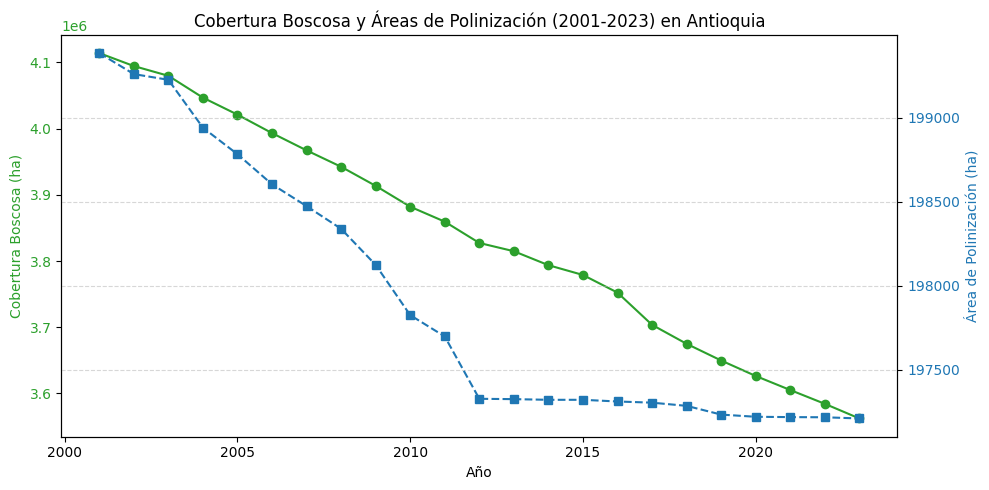

In [17]:
# =============================================================================
# 4. GRAFICADO (OBLIGATORIO AL FINAL DE LA MISMA CELDA)
# =============================================================================
fig, ax1 = plt.subplots(figsize=(10, 5))

color = "tab:green"
ax1.set_xlabel("Año")
ax1.set_ylabel("Cobertura Boscosa (ha)", color=color)
ax1.plot(
    df_resultados["year"],
    df_resultados["forest_area"],
    color=color,
    marker="o",
    label="Cobertura Boscosa",
)
ax1.tick_params(axis="y", labelcolor=color)

ax2 = ax1.twinx()
color = "tab:blue"
ax2.set_ylabel("Área de Polinización (ha)", color=color)
ax2.plot(
    df_resultados["year"],
    df_resultados["pollination_area"],
    color=color,
    marker="s",
    linestyle="--",
    label="Área de Polinización",
)
ax2.tick_params(axis="y", labelcolor=color)

plt.title("Cobertura Boscosa y Áreas de Polinización (2001-2023) en Antioquia")
plt.grid(True, linestyle="--", alpha=0.5)
fig.tight_layout()

# Forzar despliegue de la imagen en pantalla
plt.show()